# Importação das bibliotecas

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    classification_report,
    roc_curve,
    roc_auc_score,
    precision_recall_curve,
    precision_score,
    recall_score,
    f1_score
)

from xgboost import XGBClassifier
from imblearn.over_sampling import SMOTE
import shap

print("tudo certo")

c:\database\python_3\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


tudo certo


# Carregamento e exploração de dados

Distribuição das classes:
Class
0    284315
1       492
Name: count, dtype: int64

Proporção das classes:
Class
0    0.998273
1    0.001727
Name: proportion, dtype: float64

Valores de Amount e Amount_log:
   Amount  Amount_log
0  149.62    5.014760
1    2.69    1.305626
2  378.66    5.939276
3  123.50    4.824306
4   69.99    4.262539
<class 'pandas.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 32 columns):
 #   Column      Non-Null Count   Dtype  
---  ------      --------------   -----  
 0   Time        284807 non-null  float64
 1   V1          284807 non-null  float64
 2   V2          284807 non-null  float64
 3   V3          284807 non-null  float64
 4   V4          284807 non-null  float64
 5   V5          284807 non-null  float64
 6   V6          284807 non-null  float64
 7   V7          284807 non-null  float64
 8   V8          284807 non-null  float64
 9   V9          284807 non-null  float64
 10  V10         284807 non-null  float64
 11  V11        

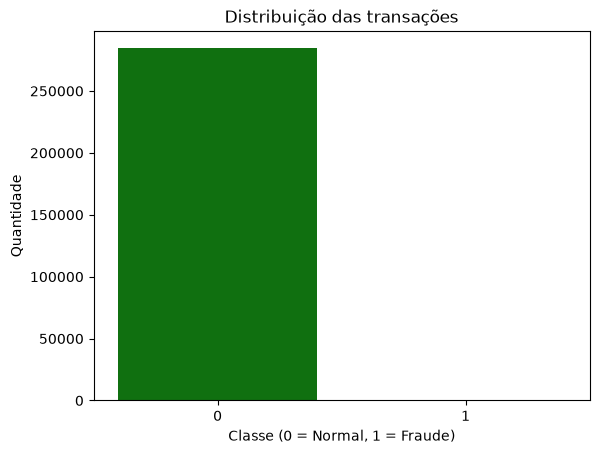

In [2]:
url = "https://storage.googleapis.com/download.tensorflow.org/data/creditcard.csv"

df = pd.read_csv(url)


print("Distribuição das classes:")
print(df["Class"].value_counts())

print("\nProporção das classes:")
print(df["Class"].value_counts(normalize=True))


df["Amount_log"] = np.log1p(df["Amount"])

print("\nValores de Amount e Amount_log:")
print(df[["Amount", "Amount_log"]].head())

df.info()


print("\nValores ausentes:")
print(df.isnull().sum().sum())


print("\nRegistros duplicados:")
print(df.duplicated().sum())

sns.countplot(data=df, x="Class", color="green")
plt.title("Distribuição das transações")
plt.xlabel("Classe (0 = Normal, 1 = Fraude)")
plt.ylabel("Quantidade")
plt.show()


# Preparação de dados e divisão treino/teste

In [3]:
X = df.drop("Class", axis=1)
y = df["Class"]


X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    stratify=y,
    test_size=0.3,
    random_state=42
)


scaler = StandardScaler()

X_train = X_train.copy()
X_test = X_test.copy()

X_train["Amount_scaled"] = scaler.fit_transform(
    X_train[["Amount"]]
)

X_test["Amount_scaled"] = scaler.transform(
    X_test[["Amount"]]
)

# Regressão de dados

In [4]:
model = LogisticRegression(max_iter=1000)

model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print("\nResultado da Regressão Logística:")
print(classification_report(y_test, y_pred))



Resultado da Regressão Logística:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     85295
           1       0.87      0.70      0.77       148

    accuracy                           1.00     85443
   macro avg       0.94      0.85      0.89     85443
weighted avg       1.00      1.00      1.00     85443



c:\database\python_3\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


# Curva ROC e AUC

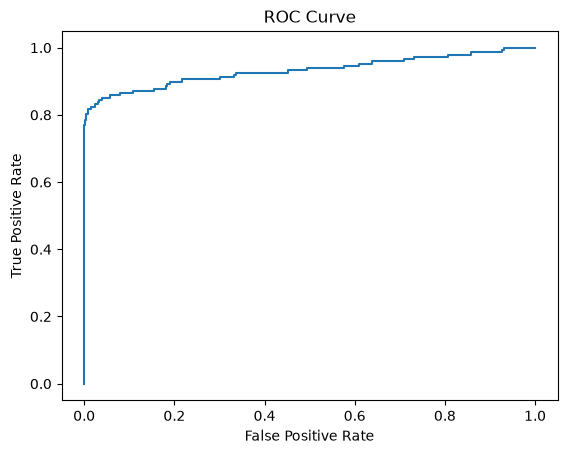

AUC: 0.9320157545434524


In [5]:
y_probs = model.predict_proba(X_test)[:, 1]

fpr, tpr, _ = roc_curve(y_test, y_probs)

plt.plot(fpr, tpr)
plt.title("ROC Curve")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.show()

print("AUC:", roc_auc_score(y_test, y_probs))


# Curva PRECISION-RECALL

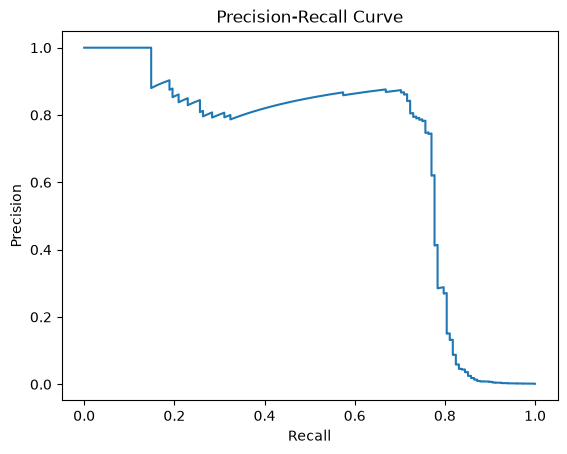

In [6]:
precision, recall, _ = precision_recall_curve(
    y_test,
    y_probs
)

plt.plot(recall, precision)
plt.title("Precision-Recall Curve")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.show()


# Undersampling

In [7]:

dados_treino = X_train.copy()
dados_treino["Class"] = y_train


fraudes = dados_treino[dados_treino["Class"] == 1]
normais = dados_treino[dados_treino["Class"] == 0]


normais_under = normais.sample(
    n=len(fraudes),
    random_state=42
)


df_under = pd.concat([fraudes, normais_under])


df_under = df_under.sample(frac=1, random_state=42)


X_train_under = df_under.drop("Class", axis=1)
y_train_under = df_under["Class"]


print("\nAntes do undersampling:")
print(y_train.value_counts())

print("\nDepois do undersampling:")
print(y_train_under.value_counts())


model_under = LogisticRegression(max_iter=1000)

model_under.fit(X_train_under, y_train_under)


y_pred_under = model_under.predict(X_test)

print("\nResultado com Undersampling:")
print(classification_report(y_test, y_pred_under))



Antes do undersampling:
Class
0    199020
1       344
Name: count, dtype: int64

Depois do undersampling:
Class
1    344
0    344
Name: count, dtype: int64

Resultado com Undersampling:
              precision    recall  f1-score   support

           0       1.00      0.97      0.98     85295
           1       0.05      0.88      0.09       148

    accuracy                           0.97     85443
   macro avg       0.52      0.92      0.54     85443
weighted avg       1.00      0.97      0.98     85443



c:\database\python_3\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


# Oversampling com SMOTE

In [8]:
smote = SMOTE(random_state=42)


X_train_smote, y_train_smote = smote.fit_resample(
    X_train,
    y_train
)


print("\nDepois do SMOTE:")
print(y_train_smote.value_counts())


model_smote = LogisticRegression(max_iter=1000)

model_smote.fit(X_train_smote, y_train_smote)


y_pred_smote = model_smote.predict(X_test)

print("\nResultado com SMOTE:")
print(classification_report(y_test, y_pred_smote))


Depois do SMOTE:
Class
0    199020
1    199020
Name: count, dtype: int64

Resultado com SMOTE:
              precision    recall  f1-score   support

           0       1.00      0.99      0.99     85295
           1       0.11      0.84      0.20       148

    accuracy                           0.99     85443
   macro avg       0.56      0.92      0.60     85443
weighted avg       1.00      0.99      0.99     85443



c:\database\python_3\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


# Random forest

In [9]:
rf = RandomForestClassifier(
    n_estimators=50,
    max_depth=10,
    class_weight="balanced",
    n_jobs=-1,
    random_state=42
)

rf.fit(X_train, y_train)

y_pred_rf = rf.predict(X_test)

print("\nResultado do Random Forest:")
print(classification_report(y_test, y_pred_rf))


Resultado do Random Forest:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     85295
           1       0.74      0.80      0.77       148

    accuracy                           1.00     85443
   macro avg       0.87      0.90      0.89     85443
weighted avg       1.00      1.00      1.00     85443



# Ajuste de threshould da regressão logística

In [10]:
threshold = 0.3

y_pred_custom = (y_probs >= threshold).astype(int)

print("\nRegressão Logística com threshold 0.3:")
print(classification_report(y_test, y_pred_custom))


Regressão Logística com threshold 0.3:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     85295
           1       0.84      0.72      0.77       148

    accuracy                           1.00     85443
   macro avg       0.92      0.86      0.89     85443
weighted avg       1.00      1.00      1.00     85443



# XGBOOST

In [11]:
xgb = XGBClassifier(
    scale_pos_weight=10,
    eval_metric="logloss"
)

xgb.fit(X_train, y_train)

y_pred_xgb = xgb.predict(X_test)

print("\nResultado do XGBoost:")
print(classification_report(y_test, y_pred_xgb))


Resultado do XGBoost:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     85295
           1       0.94      0.78      0.85       148

    accuracy                           1.00     85443
   macro avg       0.97      0.89      0.93     85443
weighted avg       1.00      1.00      1.00     85443



# Ajuste de threshould do XGBOOST

In [12]:

xgb_probs = xgb.predict_proba(X_test)[:, 1]

threshold_xgb = 0.3

y_pred_xgb_custom = (
    xgb_probs >= threshold_xgb
).astype(int)

print("\nXGBoost com threshold 0.3:")
print(classification_report(y_test, y_pred_xgb_custom))


XGBoost com threshold 0.3:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     85295
           1       0.91      0.79      0.84       148

    accuracy                           1.00     85443
   macro avg       0.95      0.90      0.92     85443
weighted avg       1.00      1.00      1.00     85443



# Importância das variáveis

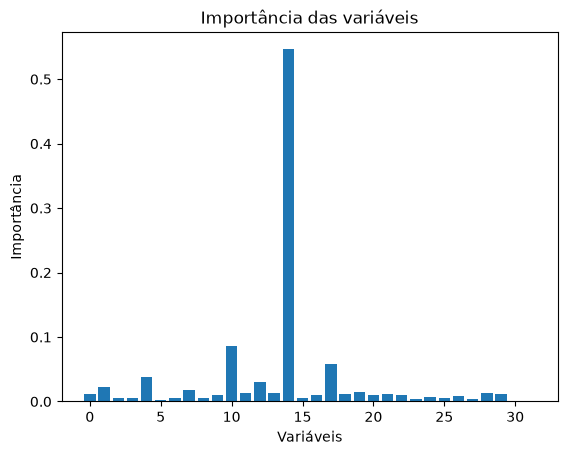

In [13]:
importancias = xgb.feature_importances_

plt.bar(range(len(importancias)), importancias)
plt.title("Importância das variáveis")
plt.xlabel("Variáveis")
plt.ylabel("Importância")
plt.show()

# GridSearchCV

In [14]:
param_grid = {
    "max_depth": [3, 5],
    "n_estimators": [50, 100]
}

grid = GridSearchCV(
    XGBClassifier(
        eval_metric="logloss",
        scale_pos_weight=10
    ),
    param_grid,
    scoring="recall",
    cv=3,
    n_jobs=-1
)

grid.fit(X_train, y_train)

print("\nMelhores parâmetros:")
print(grid.best_params_)

print("Melhor Recall:")
print(grid.best_score_)




Melhores parâmetros:
{'max_depth': 3, 'n_estimators': 50}
Melhor Recall:
0.8284515636918384


# Explicabilidade com Shap

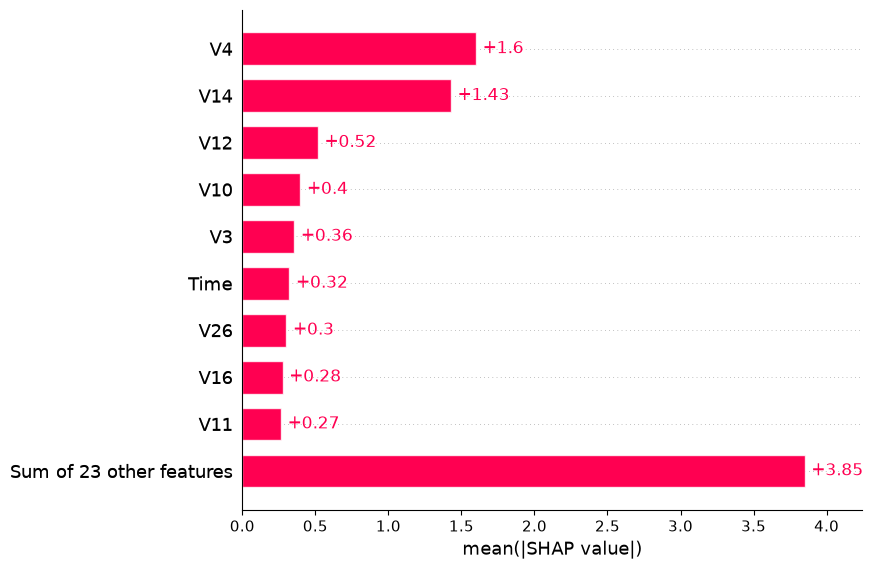

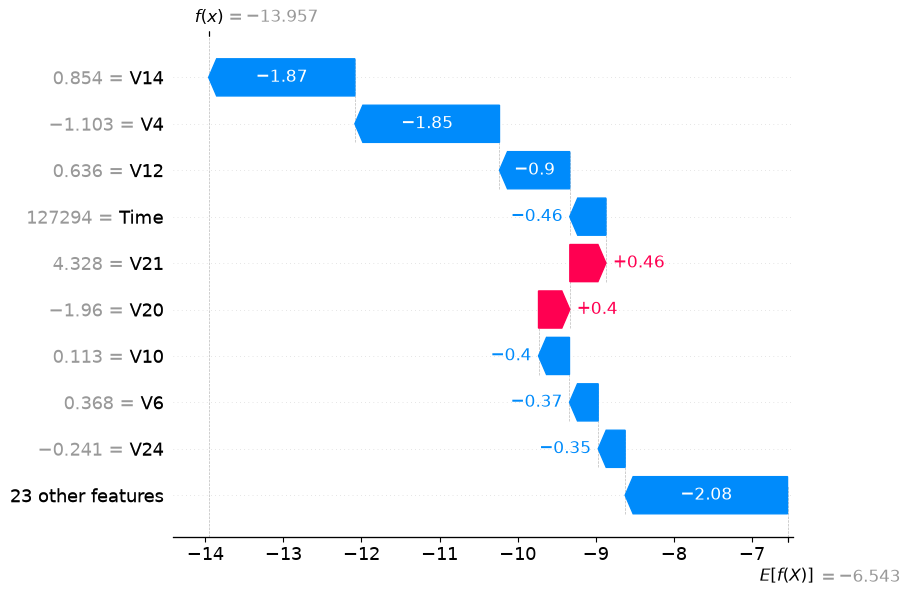

In [15]:
explainer = shap.Explainer(xgb)

shap_values = explainer(X_test.iloc[:100])


shap.plots.bar(shap_values)


shap.plots.waterfall(shap_values[0])


# Comparação dos modelos

In [16]:
pred_log = model.predict(X_test)
pred_rf = rf.predict(X_test)
pred_xgb = xgb.predict(X_test)
pred_under = model_under.predict(X_test)
pred_smote = model_smote.predict(X_test)

resultados = {
    "Modelo": [
        "Regressão Logística",
        "Random Forest",
        "XGBoost",
        "Logística com Undersampling",
        "Logística com SMOTE"
    ],

    "Precision": [
        precision_score(y_test, pred_log),
        precision_score(y_test, pred_rf),
        precision_score(y_test, pred_xgb),
        precision_score(y_test, pred_under),
        precision_score(y_test, pred_smote)
    ],

    "Recall": [
        recall_score(y_test, pred_log),
        recall_score(y_test, pred_rf),
        recall_score(y_test, pred_xgb),
        recall_score(y_test, pred_under),
        recall_score(y_test, pred_smote)
    ],

    "F1-score": [
        f1_score(y_test, pred_log),
        f1_score(y_test, pred_rf),
        f1_score(y_test, pred_xgb),
        f1_score(y_test, pred_under),
        f1_score(y_test, pred_smote)
    ]
}

comparacao = pd.DataFrame(resultados)

print("\nComparação dos modelos:")
print(comparacao)



Comparação dos modelos:
                        Modelo  Precision    Recall  F1-score
0          Regressão Logística   0.872881  0.695946  0.774436
1                Random Forest   0.743750  0.804054  0.772727
2                      XGBoost   0.942623  0.777027  0.851852
3  Logística com Undersampling   0.048417  0.878378  0.091776
4          Logística com SMOTE   0.113327  0.844595  0.199840
